<div style="border-left:8px solid #EF3124;padding:6px 0 6px 22px">
<p style="color:#6F2BFE;font-weight:700;letter-spacing:1px">АЛЬФА-БАНК · ПРАКТИЧЕСКОЕ ЗАНЯТИЕ</p>
<h1 style="margin:8px 0 14px">Первый анализ<br>финансовой таблицы</h1>
<p style="font-size:20px">Jupyter Notebook, основы Python и pandas</p>
</div>

**Начинаем с нуля:** запускаем первые команды, загружаем покупки из CSV, выбираем нужные строки и получаем понятные выводы

В конце вы сможете самостоятельно ответить: **сколько потрачено, какие покупки самые крупные и на какие категории приходится больше денег**

Рабочие примеры уже выполнены: под кодом видны результаты. На занятии запускайте их сами и меняйте значения. Ячейки с надписью **«Ваш код»** предназначены для самостоятельной работы

### Маршрут

[0. Открываем ноутбук](#start) · [1. Запускаем ячейки](#cells) · [2. Основы Python](#python)  
[3. Загружаем таблицу](#load) · [4. Выбираем и фильтруем](#filter) · [5. Находим пропуски](#missing)  
[6. Считаем и сравниваем](#analysis) · [7. Собираем свой результат](#result)

В конце: [необязательный пример МКБ](#mkb), [шпаргалка](#cheatsheet), [помощь при ошибках](#errors) и [подсказки с решениями](#answers)

<a id="start"></a>
## 0. Что такое ноутбук и как его открыть

**Jupyter Notebook — документ, в котором рядом находятся объяснение, код и результат его выполнения**

Файл ноутбука заканчивается на `.ipynb`. Его открывают в специальной среде: например, JupyterLab или Google Colab

| Часть документа | Что с ней делаем |
|---|---|
| Текстовая ячейка | Читаем объяснение, условие или вывод |
| Ячейка с кодом | Запускаем команды Python и редактируем их |
| Результат под кодом | Рассматриваем число, текст, таблицу или график |

Сам файл `.ipynb` хранит текст, команды и сохранённые результаты. Для **выполнения** команд нужна запущенная среда Python

**Если вы пока открыли только HTML-версию:** её удобно читать в браузере, но выполнять и менять код нужно в `.ipynb`

### Основной способ: Google Colab в браузере

Потребуются интернет и аккаунт Google

1. Распакуйте архив занятия. Найдите `01_Практика_Python_Pandas.ipynb` и два CSV: `payments.csv` и `mkb_contracts_sample.csv`
2. Откройте [colab.research.google.com](https://colab.research.google.com/)
3. Через **Файл → Открыть блокнот → Загрузить** выберите файл `.ipynb`. В английском интерфейсе это **File → Open notebook → Upload**
4. Если предлагается сохранить копию на Диске, сохраните её — так ваши изменения останутся у вас
5. В левой панели откройте **Файлы** — значок папки — и загрузите **оба CSV** из архива. Их нужно загрузить в ту же текущую папку, а не внутрь `sample_data`
6. Нажмите **Подключиться / Connect**, если среда ещё не подключена. Подойдёт обычная среда с Python 3
7. Перейдите к разделу 1 и запустите первую ячейку

Названия пунктов могут немного различаться. Важно загрузить **ноутбук через меню открытия**, а **CSV — через панель файлов слева**

> Данные в рабочей среде Colab временные. После удаления или сброса среды CSV придётся загрузить заново. Изменения ноутбука сохраняйте на Диске или скачивайте через меню **Файл**

<details>
<summary><strong>Если в вузе уже настроен JupyterLab или Jupyter Notebook</strong></summary>

Загрузите `.ipynb` и оба CSV в одну папку. Откройте ноутбук и выберите ядро **Python 3**. Файлы должны лежать рядом с ноутбуком, без дополнительной вложенной папки

Если среда ещё не установлена, для этого занятия проще воспользоваться Colab. Инструкция для локальной установки есть в файле `README.md` из архива

</details>

<a id="cells"></a>
## 1. Первая команда: вы уже можете запустить код

Щёлкните внутри ячейки с кодом ниже и нажмите **Shift + Enter**. Этот способ работает и в Colab, и в Jupyter

В Colab также есть кнопка запуска слева от ячейки

Команда `print(...)` выводит на экран то, что записано в круглых скобках. Кавычки показывают, что внутри находится текст

In [2]:
print("Я запустил свою вторую ячейку")

Я запустил свою вторую ячейку


**Попробуйте:** замените текст внутри кавычек на короткую фразу о себе и снова нажмите **Shift + Enter**

Результат под ячейкой обновится. Изменить текст команды и запустить команду — два отдельных действия

### Как ноутбук помнит вашу работу

Команды выполняет **ядро** — запущенная программа Python. Оно запоминает созданные значения, пока работает

- Запускайте ячейки **сверху вниз**
- Изменение кода само по себе не меняет результат: ячейку нужно запустить
- Если вы изменили значение в ранней ячейке, перезапустите зависящие от неё ячейки ниже
- После перезапуска ядра память очищается. Выполните код с начала

В Jupyter номер вроде `[7]` рядом с кодом означает **порядок выполнения**, а не номер страницы. `[*]` означает, что ячейка ещё выполняется

Чтобы восстановить исходную последовательность, используйте **Перезапустить ядро и выполнить всё / Restart Kernel and Run All**. В Colab перезапустите сеанс, затем выполните все ячейки. Самостоятельные задания можно заполнять постепенно: их пустые заготовки не мешают запуску готовых примеров

<a id="python"></a>
## 2. Python: маленькие команды с понятным результатом

### 2.1. Считаем как на калькуляторе

Покупка стоит 1 200 ₽. Учебная комиссия — 2% от суммы. Сколько это в рублях?

В Python умножение записывается как `*`, деление — как `/`

In [3]:
1200 * 2 / 100

24.0

In [4]:
1200 * 0.02

24.0

Получилось **24 ₽**: два процента от 1 200 ₽

| Запись | Значение |
|---|---|
| `1200 + 300` | Сложение |
| `1200 - 300` | Вычитание |
| `1200 * 2` | Умножение |
| `1200 / 2` | Деление |
| `(1200 + 300) * 2` | Скобки задают порядок действий |

В коде число пишем без пробела между разрядами: `1200`. Для дробной части используем **точку**: `1.5`

### 2.2. Даём значениям имена

**Переменная — имя, по которому можно обратиться к сохранённому значению**

Запись `amount = 2000` означает: сохранить число `2000` под именем `amount`. Знак `=` здесь выполняет присваивание

Слово после `#` — комментарий для человека. Python его не выполняет

In [7]:
amount = 3000              # Сумма покупки в рублях
commission_percent = 1.5   # Учебная комиссия в процентах

Теперь используем эти имена в расчёте. `print` умеет выводить несколько значений: перечисляем их через запятую

In [6]:
commission = amount * commission_percent / 100
print("Комиссия:", commission, "₽")

Комиссия: 30.0 ₽


**Попробуйте:** измените `amount` на `3000` в предыдущей ячейке. Запустите **обе** ячейки: сначала со значением, затем с расчётом

Ожидаемый результат — **45 ₽**. Если осталось 30 ₽, проверьте, перезапустили ли вы ячейку с новым значением

Имена `amount` и `commission_percent` выбраны нами. Для своих переменных используйте понятные имена латиницей, без пробелов. Регистр важен: `amount` и `Amount` — разные имена

### Задание 1. Комиссия за другую покупку

Покупка стоит **2 500 ₽**, учебная комиссия — **1,5%**. Создайте переменные `purchase` и `rate`, посчитайте комиссию и выведите результат

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [ ]:
# Ваш код

### 2.3. Число, текст и ответ «да / нет»

Значения бывают разных типов. От типа зависит, что с ними можно сделать

| Что храним | Пример Python | Название типа |
|---|---|---|
| Целое число | `1200` | `int` |
| Число с дробной частью | `1.5` | `float` |
| Текст, или строку | `"Кафе"` | `str` |
| Логический ответ | `True` или `False` | `bool` |

У строки есть кавычки. У чисел и логических значений кавычки не нужны

In [8]:
category = "Кафе"
print(category)

Кафе


Даже цифры в кавычках становятся текстом. Посмотрите, что получится, если соединить две такие строки

In [9]:
"1200" + "300"

'1200300'

Получилось `"1200300"`: знак `+` соединил текст. Для арифметики нам нужны числа без кавычек

### 2.4. Проверяем условие

`amount > 1000` — вопрос: «Сумма больше тысячи?» Результат — `True`, если да, и `False`, если нет

In [10]:
amount > 1000

True

| Знак | Как читать |
|---|---|
| `>` и `<` | Больше и меньше |
| `>=` и `<=` | Не меньше и не больше |
| `==` | Равно? |
| `!=` | Не равно? |

**Различайте:** `=` сохраняет значение, `==` сравнивает значения. Это понадобится при отборе покупок

### 2.5. Список: несколько значений вместе

Список записывают в **квадратных скобках**, элементы разделяют запятыми. Вот суммы трёх покупок

In [11]:
amounts = [450, 1200, 300]
amounts

[450, 1200, 300]

Чтобы взять один элемент, указываем его позицию в квадратных скобках. **Первая позиция в Python — 0**

In [12]:
amounts[0]

450

`len(...)` считает количество элементов. Это готовая функция: передаём ей список в круглых скобках

In [13]:
len(amounts)

3

### Задание 2. Прочитайте список

Создайте список `channels = ["Карта", "Онлайн", "Карта"]`. Выведите **второй** элемент и количество элементов в списке

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [14]:
# Ваш код

**Что уже умеем:** вычислять выражения, сохранять значения, выводить текст, проверять условия и работать с коротким списком

Дальше те же идеи помогут выбирать столбцы и строки в таблице

<a id="load"></a>
## 3. Загружаем финансовую таблицу

### Задача: понять структуру покупок

Представьте, что у нас есть небольшая выгрузка оплат. Хотим узнать, какие покупки были, где суммы больше и сколько потрачено по категориям

**Одна строка — одна покупка**

В `payments.csv` **30 вымышленных покупок и 6 столбцов**. Таблица создана для обучения: это не данные клиентов и не тарифы банка

| Столбец | Что означает | Пример |
|---|---|---|
| `operation_id` | Уникальный номер операции | `1001` |
| `date` | Дата покупки | `2026-10-01` |
| `category` | Категория покупки | `Супермаркеты` |
| `channel` | Канал оплаты | `Карта` или `Онлайн` |
| `amount_rub` | Сумма покупки в рублях | `2450` |
| `cashback_percent` | Условная ставка кэшбэка, % | `1` означает 1% |

Значения `Карта` и `Онлайн` в этой учебной таблице — две отдельные категории канала. У некоторых покупок категория не указана: чуть позже разберём, как это заметить

### 3.1. Подключаем pandas

**Библиотека — набор готовых инструментов.** Библиотека pandas помогает читать и анализировать таблицы

Команда `import pandas as pd` подключает библиотеку и даёт ей короткое имя `pd`. Это стандартное сокращение

In [15]:
import pandas as pd

### 3.2. Читаем CSV

CSV — обычный текстовый файл с таблицей: первая строка содержит названия столбцов, следующие — значения

У нашего файла разделитель — запятая. Так выглядят его первые строки:

```text
operation_id,date,category,channel,amount_rub,cashback_percent
1001,2026-10-01,Супермаркеты,Карта,2450,1
1002,2026-10-01,Кафе,Карта,450,3
```

`pd.read_csv(...)` читает файл. Полученную таблицу сохраним в переменную `payments`

In [16]:
payments = pd.read_csv("payments.csv")

Эта ячейка ничего не напечатала: мы сохранили таблицу в память. Теперь посмотрим первые строки командой `head()`

In [17]:
payments.head()

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
1,1002,2026-10-01,Кафе,Карта,450,3
2,1003,2026-10-01,Транспорт,Карта,180,0
3,1004,2026-10-02,Аптеки,Карта,1350,1
4,1005,2026-10-02,Кафе,Онлайн,320,3


**DataFrame** — название таблицы в pandas. Слева от неё виден **индекс строки**, обычно начинающийся с 0. Он не совпадает с `operation_id`: индекс — метка строки в pandas, а номер операции — отдельный столбец

`head()` по умолчанию показывает первые пять строк. Если нужны три, можно написать `head(3)`

### Как читать такую команду

- `payments` — наша таблица
- Точка `.` — обращение к её инструменту или свойству
- `head()` — действие «показать начало»
- Число в скобках, например `3`, — настройка действия

Готовое действие, которое вызывается через точку, часто называют **методом**

### 3.3. Проверяем размер и названия

`shape` возвращает два числа: **количество строк, количество столбцов**. После него не нужны `()`: это свойство таблицы, а не действие

In [22]:
payments.shape

(30, 6)

Получилось `(30, 6)`: 30 покупок и 6 столбцов

In [23]:
payments.columns

Index(['operation_id', 'date', 'category', 'channel', 'amount_rub',
       'cashback_percent'],
      dtype='object')

Это точные названия столбцов. При обращении к столбцу копируйте имя целиком: `amount_rub` и `Amount_rub` не совпадают

Посмотрим, какие типы значений pandas распознал в столбцах

In [25]:
payments.dtypes

,0
operation_id,int64
date,object
category,object
channel,object
amount_rub,int64
cashback_percent,int64


`int64` означает целые числа, `float64` — числа с дробной частью. Текст может обозначаться как `object`, `str` или `string` в зависимости от версии pandas

Идентификатор может храниться числом, но среднее значение номера операции не имеет полезного смысла. Тип хранения и смысл столбца — разные вещи

Дату пока оставляем текстом. Для сегодняшних вопросов преобразование даты не требуется

<a id="filter"></a>
## 4. Выбираем нужное из таблицы

### 4.1. Один столбец

В квадратных скобках пишем точное имя столбца в кавычках. Добавим `head()`, чтобы посмотреть только начало

In [26]:
payments["amount_rub"].head()

,amount_rub
0,2450
1,450
2,180
3,1350
4,320


Один столбец в pandas называется **Series**. У него тоже есть индекс

### 4.2. Несколько столбцов

Внутри скобок передаём **список названий**. Поэтому квадратных скобок две пары: внешние выбирают данные, внутренние задают список

In [27]:
payments[["category", "amount_rub"]].head()

,category,amount_rub
0,Супермаркеты,2450
1,Кафе,450
2,Транспорт,180
3,Аптеки,1350
4,Кафе,320


### Задание 3. Соберите короткий просмотр

Покажите первые **три** строки только со столбцами `channel` и `amount_rub`

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [ ]:
# Ваш код

### 4.3. Находим самые крупные покупки

`sort_values` сортирует строки по выбранному столбцу. Настройка `ascending=False` означает **по убыванию**

Сначала сортируем, затем показываем первые пять строк

In [ ]:
payments.sort_values("amount_rub", ascending=False).head()

,operation_id,date,category,channel,amount_rub,cashback_percent
11,1012,2026-10-04,Электроника,Онлайн,24000,1
20,1021,2026-10-07,Супермаркеты,Карта,5100,1
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1
28,1029,2026-10-10,Супермаркеты,Онлайн,3250,1
14,1015,2026-10-05,Супермаркеты,Онлайн,2950,1


Первая операция — покупка электроники за **24 000 ₽**. При сортировке индекс переехал вместе со строкой, поэтому числа слева идут не по порядку

Эта команда показала отсортированный результат. Переменная `payments` по-прежнему хранит исходный порядок: для сохранения результата нужно присваивание через `=`

### 4.4. Отбираем строки по условию

Нужны покупки дороже 1 000 ₽. Сначала зададим вопрос **для каждой строки**

In [40]:
is_large = payments["amount_rub"] > 1000
is_large.head()

,amount_rub
0,True
1,False
2,False
3,True
4,False


Получился столбец из `True` и `False`: оставить покупку или нет. Такой набор ответов называют **логической маской**

Теперь передадим маску таблице в квадратных скобках

In [41]:
large_payments = payments[is_large]
large_payments.head()

,operation_id,date,category,channel,amount_rub,cashback_percent
0,1001,2026-10-01,Супермаркеты,Карта,2450,1
3,1004,2026-10-02,Аптеки,Карта,1350,1
5,1006,2026-10-02,Супермаркеты,Онлайн,3800,1
6,1007,2026-10-03,Развлечения,Онлайн,1200,5
8,1009,2026-10-03,Супермаркеты,Карта,1750,1


В `large_payments` попали строки, где условие было `True`. Размер исходной таблицы `payments` от этого не изменился

Тот же отбор можно записать одной строкой:

```python
payments[payments["amount_rub"] > 1000]
```

Сначала Python вычисляет условие внутри скобок, затем оставляет подходящие строки

### Задание 4. Покупки дороже 3 000 ₽

Сохраните в `above_3000` все покупки **строго дороже** 3 000 ₽. Покажите их и посчитайте количество с помощью `len(...)`

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [ ]:
# Ваш код

### 4.5. Отбираем по тексту

Чтобы оставить только кафе, сравним категорию с текстом `"Кафе"`. Здесь нужен знак `==`

In [42]:
payments[payments["category"] == "Кафе"]

,operation_id,date,category,channel,amount_rub,cashback_percent
1,1002,2026-10-01,Кафе,Карта,450,3
4,1005,2026-10-02,Кафе,Онлайн,320,3
9,1010,2026-10-04,Кафе,Карта,590,3
12,1013,2026-10-05,Кафе,Карта,410,3
17,1018,2026-10-06,Кафе,Карта,680,3
21,1022,2026-10-08,Кафе,Онлайн,350,3
27,1028,2026-10-10,Кафе,Карта,540,3


### 4.6. Два условия одновременно

Хотим оставить покупки в кафе на сумму **не меньше 500 ₽**. Составим два условия отдельно и соединим знаком `&` — **«и»**

In [43]:
is_cafe = payments["category"] == "Кафе"
at_least_500 = payments["amount_rub"] >= 500
payments[is_cafe & at_least_500]

,operation_id,date,category,channel,amount_rub,cashback_percent
9,1010,2026-10-04,Кафе,Карта,590,3
17,1018,2026-10-06,Кафе,Карта,680,3
27,1028,2026-10-10,Кафе,Карта,540,3


Остаются только строки, где выполнены **оба** условия

Если писать сравнения сразу внутри отбора, каждое нужно заключить в круглые скобки:

```python
payments[(payments["category"] == "Кафе") & (payments["amount_rub"] >= 500)]
```

Можно пользоваться более длинным вариантом с двумя именами условий — его проще читать. Для соединения условий по целым столбцам используем `&`

### Задание 5. Онлайн-покупки от 2 000 ₽

Выберите покупки с каналом `"Онлайн"` и суммой **от 2 000 ₽ включительно**. Сохраните результат в `online_2000` и посчитайте строки

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [44]:
# Ваш код

<a id="missing"></a>
## 5. Замечаем, что в данных чего-то не хватает

У двух покупок не указана категория. pandas показывает пропуск как `NaN` или `<NA>`. **Пропуск не означает ноль**

Команда `isna()` проверяет наличие пропуска. Следующий за ней `sum()` считает ответы `True` — по одному за каждый пропуск

In [45]:
payments.isna().sum()

,0
operation_id,0
date,0
category,2
channel,0
amount_rub,0
cashback_percent,0


В `category` — **2 пропуска**, в остальных столбцах — 0. Посмотрим именно на эти покупки

In [46]:
payments[payments["category"].isna()]

,operation_id,date,category,channel,amount_rub,cashback_percent
15,1016,2026-10-06,NaN,Карта,720,0
22,1023,2026-10-08,NaN,Онлайн,1600,0


Это операции **1016** и **1023**. Суммы известны, поэтому покупки нельзя просто потерять при подсчёте расходов

Для отчёта заменим пустые категории явной подписью **«Без категории»**. Мы обозначаем отсутствие информации, а не угадываем настоящую категорию

In [47]:
payments["category"] = payments["category"].fillna("Без категории")

Слева от `=` указан столбец, который обновляем. Справа `fillna(...)` возвращает значения с заменой пропусков

Изменение пока существует **в таблице в памяти**. Исходный файл `payments.csv` на диске остаётся прежним. Повторный запуск ячейки безопасен: уже заполненные значения не меняются

<a id="analysis"></a>
## 6. Получаем первые ответы

### 6.1. Сколько потрачено и каков размер покупки

- `sum()` складывает значения
- `mean()` считает среднее
- `median()` находит значение в середине упорядоченного ряда; при чётном количестве берёт среднее двух центральных

`round(..., 2)` округляет число до двух знаков после точки

In [48]:
total = payments["amount_rub"].sum()
average = payments["amount_rub"].mean()
median = payments["amount_rub"].median()

print("Всего потрачено:", total, "₽")
print("Средняя покупка:", round(average, 2), "₽")
print("Медианная покупка:", median, "₽")

Всего потрачено: 62880 ₽
Средняя покупка: 2096.0 ₽
Медианная покупка: 1035.0 ₽


**Как прочитать результат**

Всего в таблице **62 880 ₽**. Среднее — **2 096 ₽**, медиана — **1 035 ₽**

Одна покупка электроники за 24 000 ₽ заметно повышает среднее. Поэтому перед фразой «обычная покупка стоит около двух тысяч» полезно посмотреть и на медиану, и на крупные операции

Эти числа описывают именно нашу учебную таблицу. Они не являются оценкой расходов всех клиентов банка

### 6.2. Какие категории встречаются чаще

`value_counts()` считает, сколько раз встречается каждое значение

In [49]:
payments["category"].value_counts()

,count
category,
Супермаркеты,7
Кафе,7
Транспорт,5
Аптеки,4
Развлечения,4
Без категории,2
Электроника,1


В супермаркетах и кафе — по **7 покупок**. Но частота покупок ещё не говорит, где потрачено больше денег

### 6.3. Сколько денег в каждой категории

`groupby("category")` собирает строки по категориям. Затем выбираем сумму покупки и складываем её внутри каждой группы

In [50]:
spending_by_category = payments.groupby("category")["amount_rub"].sum()
spending_by_category

,amount_rub
category,
Аптеки,4820
Без категории,2320
Кафе,3340
Развлечения,6150
Супермаркеты,21280
Транспорт,970
Электроника,24000


Прочитаем команду по частям:

1. `groupby("category")` — разделить покупки на группы
2. `["amount_rub"]` — взять суммы покупок
3. `sum()` — сложить их отдельно в каждой группе

Для такого расчёта не нужно вручную перебирать строки. pandas выполняет действие сразу для всей таблицы

Теперь упорядочим категории по сумме

In [51]:
spending_by_category.sort_values(ascending=False)

,amount_rub
category,
Электроника,24000
Супермаркеты,21280
Развлечения,6150
Аптеки,4820
Кафе,3340
Без категории,2320
Транспорт,970


**Два разных вывода:** кафе и супермаркеты лидируют по количеству покупок, а электроника — по общей сумме: 24 000 ₽ от одной покупки

Подпись «Без категории» тоже присутствует в результате. Эти 2 320 ₽ учтены, хотя точную категорию мы не знаем

### Задание 6. Короткий отчёт по аптекам

Отберите покупки категории `"Аптеки"`. Сколько их и на какую общую сумму? Сохраните отобранную таблицу в `pharmacy`

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [ ]:
# Ваш код

### 6.4. Сравним суммы на графике

Для графиков подключим библиотеку `matplotlib.pyplot` под коротким именем `plt`

Команда `plot.barh` рисует горизонтальные столбики. Их длина показывает сумму. Остальные строки задают подписи и показывают рисунок

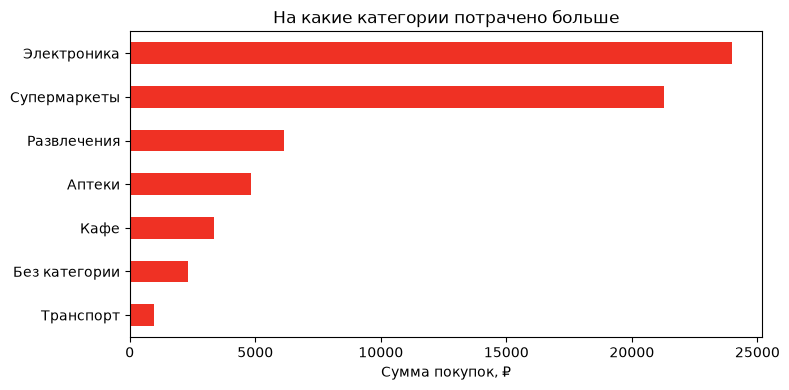

In [ ]:
import matplotlib.pyplot as plt

spending_by_category.sort_values().plot.barh(
    color="#EF3124",
    figsize=(8, 4)
)
plt.title("На какие категории потрачено больше")
plt.xlabel("Сумма покупок, ₽")
plt.ylabel("")
plt.tight_layout()
plt.show()

На графике особенно заметна крупная покупка электроники

Для проверки любой категории можно вернуться к отфильтрованным строкам. График помогает увидеть разницу, а таблица — разобраться, из каких покупок она получилась

<a id="result"></a>
## 7. Рассчитываем новый показатель и делаем свой отчёт

### 7.1. Кэшбэк в рублях

В таблице уже есть условная ставка кэшбэка в процентах. Переведём её в рубли:

**Сумма покупки × ставка / 100**

Например, для 450 ₽ при ставке 3% получится 13,5 ₽

Назначим результат новому столбцу `cashback_rub`. pandas выполнит расчёт для каждой строки

In [58]:
payments["cashback_rub"] = (
    payments["amount_rub"] * payments["cashback_percent"] / 100
)
payments[["amount_rub", "cashback_percent", "cashback_rub"]].head()

,amount_rub,cashback_percent,cashback_rub
0,2450,1,24.5
1,450,3,13.5
2,180,0,0.0
3,1350,1,13.5
4,320,3,9.6


В таблице появился дополнительный столбец, а не одно итоговое число. В первых строках видны исходная сумма, процент и рассчитанный кэшбэк

Используем упрощённое учебное правило. Реальные программы лояльности могут учитывать лимиты и дополнительные условия

### Задание 7. Проверяем кэшбэк

Посчитайте общий `cashback_rub`. Затем найдите операцию с самым большим кэшбэком: отсортируйте таблицу и покажите первую строку

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [59]:
# Ваш код

### Задание 8. Ваш первый самостоятельный анализ

Подготовьте короткий отчёт **только об онлайн-покупках**:

1. Сколько таких покупок?
2. На какую общую сумму?
3. Какая из них самая крупная? Покажите строку

Сохраните отобранную таблицу в `online_report`. После расчётов запишите **одно предложение с выводом** в текстовой ячейке ниже

Сначала напишите свой вариант в ячейке ниже. Подсказка и решение доступны в конце ноутбука.

In [60]:
# Ваш код

**Мой вывод:** напишите здесь одно предложение о результатах онлайн-покупок

*Чтобы изменить текстовую ячейку, откройте её двойным щелчком, замените эту строку и нажмите Shift + Enter*

### 7.2. Сохраняем выбранные строки в файл

Теперь умеем пройти весь путь от файла до результата. Сохраним текущую таблицу с заполненными категориями и рассчитанным кэшбэком в новый файл

`to_csv(...)` записывает таблицу в CSV. Настройка `index=False` убирает служебный индекс из файла. `encoding="utf-8-sig"` помогает корректно открыть русский текст в Excel

In [ ]:
payments.to_csv(
    "payments_result.csv",
    index=False,
    encoding="utf-8-sig"
)
print("Сохранён файл payments_result.csv")

Сохранён файл payments_result.csv


Файл появится в текущей папке рядом с ноутбуком. В Colab откройте панель **Файлы**, обновите список при необходимости и скачайте `payments_result.csv` через меню файла

В новом файле — 30 покупок и 7 столбцов, включая `cashback_rub`. Исходный `payments.csv` не перезаписан: у результата другое имя

Покупки и результаты расчётов остаются в памяти до сброса среды. Нужные файлы скачивайте, а собственные изменения ноутбука сохраняйте отдельно

### Что получилось

Вы самостоятельно запустили код, прочитали CSV, выбрали столбцы и строки, нашли пропуски, посчитали показатели, сравнили категории и сохранили результат

**Закройте код и объясните словами:**

- Чем отбор строк отличается от выбора столбцов?
- Почему категория с самой большой суммой может не лидировать по числу покупок?
- Почему отсутствие категории не означает отсутствие расхода?

К этим вопросам полезно вернуться, если какая-то команда запомнилась, но её смысл ещё не ясен

<a id="mkb"></a>
## Дополнительно. Те же команды на выгрузке МКБ

Основная практика завершена. Этот короткий блок можно пройти, если вы уверенно выполнили предыдущие задания

Исходная таблица хакатона содержит 17 891 строку и 124 столбца. Для первого знакомства мы подготовили `mkb_contracts_sample.csv` — **200 строк и три столбца** из предоставленного train-файла. Значения сохранены; состав строк выбран один раз и зафиксирован

| Столбец | Как читать |
|---|---|
| `id_contract` | Идентификатор договора |
| `id_client` | Идентификатор клиента |
| `SIGN_DATE` | Дата из исходной выгрузки, пока как текст |

Здесь нет сумм покупок и категорий из основной практики. Перед анализом новой таблицы всегда нужно разобраться в её собственных столбцах

In [ ]:
mkb = pd.read_csv("mkb_contracts_sample.csv")
mkb.head()

,id_contract,id_client,SIGN_DATE
0,60,7448,01JAN2018:00:00:00
1,102,6969,08JAN2018:00:00:00
2,104,10714,09JAN2018:00:00:00
3,124,10824,09JAN2018:00:00:00
4,128,7691,09JAN2018:00:00:00


In [ ]:
mkb.shape

(200, 3)

Знакомая пара чисел: **200 строк, 3 столбца**. Посмотрим, какие идентификаторы клиентов встречаются несколько раз

In [ ]:
mkb["id_client"].value_counts().head()

id_client
10714    4
10092    4
8677     3
10626    2
12467    2
Name: count, dtype: int64

Один клиент может встречаться в нескольких строках. Поэтому количество строк не обязательно равно количеству клиентов

Мы применили уже знакомые команды к другой таблице. Для содержательных выводов по финансовым показателям полной выгрузки потребуется описание полей и единиц измерения

<details>
<summary><strong>Как позже прочитать исходный train-файл целиком</strong></summary>

Загрузите сам файл `train_dataset_hackathon_mkb.csv` в рабочую папку. В нём другой разделитель и кодировка:

```python
mkb_full = pd.read_csv(
    "train_dataset_hackathon_mkb.csv",
    sep=";",
    encoding="cp1251"
)
```

`sep` задаёт разделитель столбцов, `encoding` — способ прочитать символы в файле. Для `payments.csv` эти настройки менять не требуется

Исходные train- и test-файлы в учебный архив не включены: для этого блока достаточно небольшой подготовленной вырезки

</details>